# Primeiro Experimento do Zero *(Nível Básico — Regressão)*

Neste notebook você não precisa saber JSON, CLI ou arquitetura interna — apenas o básico de ML:
1. Criamos um `.csv` simples de exemplo;
2. Plugamos um modelo próprio (`fit`/`predict`) e um baseline usando `run_experiment(...)`;
3. Lemos o resumo e visualizamos a tabela e o gráfico **SVG** direto na célula.

In [1]:
# Instalação automática apenas quando executado no Google Colab
import subprocess, sys
if "google.colab" in sys.modules:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "git+https://github.com/aleerangel/experimental-ml-framework.git",
    ])

In [2]:
# Helper de exibição rica (funciona em Jupyter/Colab e em Python puro)
def exibir_markdown(texto: str) -> None:
    try:
        from IPython.display import Markdown, display
        display(Markdown(texto))
    except ImportError:
        print(texto)

def exibir_svg(svg_bytes: bytes | str) -> None:
    svg_str = svg_bytes.decode("utf-8") if isinstance(svg_bytes, bytes) else svg_bytes
    try:
        from IPython.display import SVG, display
        display(SVG(svg_str))
    except ImportError:
        print(f"[Figura SVG gerada: {len(svg_str)} caracteres]")

## 1. Criando um `.csv` Simples e Definindo Seu Próprio Modelo

In [3]:
from pathlib import Path
import tempfile
import numpy as np

work_dir = Path(tempfile.mkdtemp(prefix="expml_basico_01_"))
rng = np.random.default_rng(42)
dap = rng.uniform(10.0, 30.0, size=30)
altura = 8.0 + 0.55 * dap + rng.normal(0.0, 0.8, size=30)
volume = 0.00005 * (dap ** 2) * altura + rng.normal(0.0, 0.015, size=30)

csv_path = work_dir / "meus_dados.csv"
linhas = ["dap,altura,volume"] + [f"{d:.3f},{h:.3f},{v:.4f}" for d, h, v in zip(dap, altura, volume)]
csv_path.write_text("\n".join(linhas) + "\n", encoding="utf-8")

class MeuRegressorLinear:
    def fit(self, X: np.ndarray, y: np.ndarray) -> "MeuRegressorLinear":
        X_aug = np.column_stack([X, np.ones(len(X))])
        coef, *_ = np.linalg.lstsq(X_aug, y, rcond=None)
        self.w_ = coef[:-1]
        self.b_ = float(coef[-1])
        return self

    def predict(self, X: np.ndarray) -> np.ndarray:
        return X @ self.w_ + self.b_

print("CSV de exemplo criado em:", csv_path)

CSV de exemplo criado em: /tmp/expml_basico_01_kp8xtqdu/meus_dados.csv


## 2. Rodando Tudo com `run_experiment(...)`

In [4]:
from experimental_ml import run_experiment
from experimental_ml.models import DummyBaselineModel

resultado = run_experiment(
    data=csv_path,
    target="volume",
    task="regression",
    models={
        "Baseline Média": DummyBaselineModel(strategy="mean"),
        "Meu Regressor Linear": MeuRegressorLinear(),
    },
    output_dir=work_dir / "meu_experimento",
    cv_folds=5,
    metrics=["rmse", "r2"],
)

print(resultado.summary())

=== Resumo do Experimento ===
Diretório: /tmp/expml_basico_01_kp8xtqdu/meu_experimento
Células concluídas: 10 (falhas: 0)
Líder observado (rmse): ('meu_regressor_linear', 'todas_features')
Status estatístico: 1 of 1 comparison(s) reached adjusted significance (p_adj < 0.050); 0 comparison(s) had insufficient statistical evidence to reject H0 (non-significance does not imply equivalence).

Desempenho por configuração:
  - ('baseline_m_dia', 'todas_features'): [VALID] r2=-0.1083±0.1145, rmse=0.3043±0.0487
  - ('meu_regressor_linear', 'todas_features'): [VALID] r2=0.9401±0.0251, rmse=0.0702±0.0198

Conclusão: On primary metric 'rmse' (MINIMIZE), observed leader is meu_regressor_linear/todas_features with mean=0.0702. 1 of 1 comparison(s) reached adjusted significance (p_adj < 0.050); 0 comparison(s) had insufficient statistical evidence to reject H0 (non-significance does not imply equivalence). Comparison baseline_m_dia/todas_features vs meu_regressor_linear/todas_features: diff=0.2341, 

## 3. Visualizando a Tabela e o Gráfico do Relatório Aqui no Notebook

### Tabela de Desempenho

### Predictive Performance

| Model | Scenario | Metric | Status | Mean | SD | Median | IQR | Coverage |
| :--- | :--- | :--- | :---: | ---: | ---: | ---: | ---: | ---: |
| baseline_m_dia | todas_features | r2 | VALID | -0.1083 | 0.1145 | -0.0771 | 0.1754 | 100.00% |
| baseline_m_dia | todas_features | rmse | VALID | 0.3043 | 0.0487 | 0.3043 | 0.0631 | 100.00% |
| meu_regressor_linear | todas_features | r2 | VALID | 0.9401 | 0.0251 | 0.9362 | 0.0264 | 100.00% |
| meu_regressor_linear | todas_features | rmse | VALID | 0.0702 | 0.0198 | 0.0681 | 0.0172 | 100.00% |


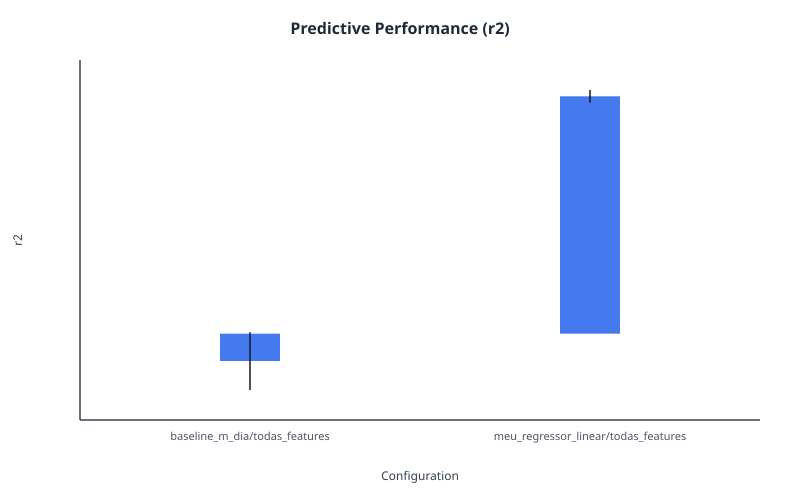

In [5]:
from experimental_ml.reporting import (
    ReportAudience,
    ReportContentSelection,
    ReportFamily,
    build_figure_spec,
    build_table_model,
    load_experiment_artifacts_readonly,
    render_figure,
    render_table_markdown,
    select_report_content,
)

loaded = load_experiment_artifacts_readonly(resultado.experiment_dir)
sel = select_report_content(loaded, ReportContentSelection(audience=ReportAudience.FULL_LAB))

tabela = build_table_model(ReportFamily.D_PREDICTIVE_PERFORMANCE, loaded, sel)
exibir_markdown("### Tabela de Desempenho\n\n" + render_table_markdown(tabela))

fig = build_figure_spec(ReportFamily.D_PREDICTIVE_PERFORMANCE, loaded, sel)
exibir_svg(render_figure(fig, fmt="svg"))